# Section 3 — The Bisection Method

[← Floating-Point Arithmetic](02_floating_point_and_error.ipynb) ·
[Module 1](README.md) ·
[Next: Fixed Points and Cobwebs →](04_fixed_point_cobwebs.ipynb)

Bisection is a robust root-finding method based on the Intermediate Value
Theorem (IVT).

If $f$ is continuous on $[a,b]$ and $f(a)f(b)<0$, then at least one root lies
in the interval.

### Learning goals

- use IVT to establish existence of a root;
- distinguish root existence from root uniqueness;
- use monotonicity to justify uniqueness;
- implement bisection;
- use the bisection error bound;
- estimate the number of iterations needed for a tolerance;
- connect Rolle's Theorem to existence arguments used elsewhere in the course.


## Supporting theorems

### Intermediate Value Theorem

If $f$ is continuous on $[a,b]$ and $f(a)f(b)<0$, then there is at least one
$p\in(a,b)$ such that $f(p)=0$.

This guarantees **existence**, not uniqueness.

### A common uniqueness argument

If $f'(x)>0$ throughout $[a,b]$, then $f$ is strictly increasing there and can
cross the $x$-axis at most once. Similarly, $f'(x)<0$ throughout the interval
implies strict decrease.

### Rolle's Theorem

If $f$ is continuous on $[a,b]$, differentiable on $(a,b)$, and
$f(a)=f(b)$, then there is a $c\in(a,b)$ such that

$$
f'(c)=0.
$$

Rolle's Theorem is not the bisection theorem, but it is part of the same
theoretical toolkit reviewed in Module 1.


In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np


## Review-style existence and uniqueness example

Consider

$$
f(x)=x^2-e^{-x}-2.5
$$

on $[1,2]$.

Because $f$ is continuous and

$$
f(1)<0,\qquad f(2)>0,
$$

IVT guarantees at least one root.

Also,

$$
f'(x)=2x+e^{-x}>0
$$

for every $x\in[1,2]$. Therefore $f$ is strictly increasing and the root is
unique.


In [2]:
def review_function(x):
    """Function used in the Exam 1 review bisection problem."""
    return x**2 - math.exp(-x) - 2.5


print(f"f(1) = {review_function(1.0):.6f}")
print(f"f(2) = {review_function(2.0):.6f}")


f(1) = -1.867879
f(2) = 1.364665


## Bisection algorithm

At each step,

$$
p_n=\frac{a_n+b_n}{2}.
$$

Retain the half-interval whose endpoint values have opposite signs.


In [3]:
def bisection(function, a, b, tolerance=1.0e-8, max_iterations=100):
    """Approximate a root using the bisection method."""
    if function(a) * function(b) >= 0:
        raise ValueError("Endpoint values must have opposite signs.")

    history = []

    for iteration in range(1, max_iterations + 1):
        p = (a + b) / 2.0
        f_p = function(p)
        history.append((iteration, a, b, p, f_p))

        if f_p == 0 or (b - a) / 2.0 < tolerance:
            return p, history

        if function(a) * f_p < 0:
            b = p
        else:
            a = p

    return p, history


root, history = bisection(review_function, 1.0, 2.0)

print(" n        a_n        b_n        p_n       f(p_n)")
for iteration, a, b, p, f_p in history[:6]:
    print(
        f"{iteration:2d}  {a:10.7f} {b:10.7f} "
        f"{p:10.7f} {f_p:11.4e}"
    )

print(f"\napproximate root = {root:.10f}")


 n        a_n        b_n        p_n       f(p_n)
 1   1.0000000  2.0000000  1.5000000 -4.7313e-01
 2   1.5000000  2.0000000  1.7500000  3.8873e-01
 3   1.5000000  1.7500000  1.6250000 -5.6287e-02
 4   1.6250000  1.7500000  1.6875000  1.6267e-01
 5   1.6250000  1.6875000  1.6562500  5.2311e-02
 6   1.6250000  1.6562500  1.6406250 -2.2085e-03

approximate root = 1.6412604079


## Error bound and required iterations

After $n$ bisections,

$$
|p_n-p|\le\frac{b-a}{2^n}.
$$

To guarantee error below a tolerance `TOL`, it is sufficient to choose $n$ so

$$
\frac{b-a}{2^n}<\mathrm{TOL}.
$$


In [4]:
a = 1.0
b = 2.0
tolerance = 1.0e-6

required_iterations = math.ceil(
    math.log2((b - a) / tolerance)
)

print(f"required iterations = {required_iterations}")


required iterations = 20


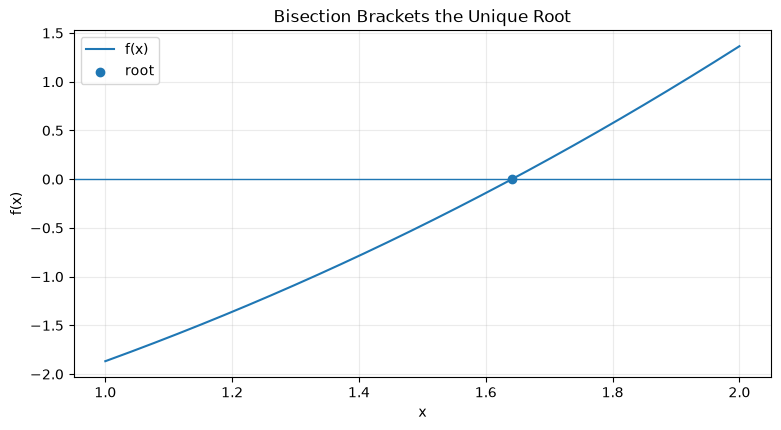

In [5]:
x_values = np.linspace(1.0, 2.0, 300)
y_values = x_values**2 - np.exp(-x_values) - 2.5

plt.figure(figsize=(9, 4.5))
plt.plot(x_values, y_values, label="f(x)")
plt.axhline(0.0, linewidth=1)
plt.scatter([root], [0.0], zorder=3, label="root")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Bisection Brackets the Unique Root")
plt.grid(alpha=0.25)
plt.legend()
plt.show()


### References

- Leon Q. Brin, *Tea Time Numerical Analysis*.
- Richard L. Burden and J. Douglas Faires, *Numerical Analysis*.
- MAD 4401 Exam 1 review.

[← Floating-Point Arithmetic](02_floating_point_and_error.ipynb) ·
[Next: Fixed Points and Cobwebs →](04_fixed_point_cobwebs.ipynb)
